In [1]:
##import packages
import open3d as o3d
import numpy as np
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import os
from sklearn.decomposition import PCA

def circle_fit_func(xy, cx, cy, r):
    """
    定义圆形拟合的函数
    xy: 点云数据的二维坐标数组 (x, y)
    cx, cy: 圆心坐标
    r: 半径
    返回值: 拟合结果数组
    """
    x, y = xy
    return (x - cx)**2 + (y - cy)**2 - r**2

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
##--------------------------读取点云数据--------------------------
pointcloud = pd.read_csv(r'D:\\Desktop\\LiDAR_course\\1119\\Output\\Segmentation_leafoff.txt',delimiter='\t')
Label = pointcloud['Segmentation'].unique()
print('树的数目：',len(Label),'棵，包括了',np.array(np.sort(Label),np.int32))

spth = r'D:\\Desktop\\LiDAR_course\\1119\\Output\\ExtractPara'  # 设置保存路径

树的数目： 17 棵，包括了 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


0 TreeHeight is: 8.9773 m
0 DBH is: 60.49918392136189 cm
********************
1 TreeHeight is: 1.6221999999999994 m
1 DBH is: 38.99097340583933 cm
********************
2 TreeHeight is: 4.769800000000004 m
2 DBH is: 22.542029178915392 cm
********************
3 TreeHeight is: 0.3760000000000048 m
3 DBH is: 0 cm
********************
4 TreeHeight is: 5.797600000000003 m
4 DBH is: 38.58718740146046 cm
********************
5 TreeHeight is: 0.25150000000000006 m
5 DBH is: 0 cm
********************


D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:223: RuntimeWarning: invalid value encountered in true_divide
  subok=False)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:254: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
D:\Programs\anaconda3\envs\L

6 TreeHeight is: 12.536299999999997 m


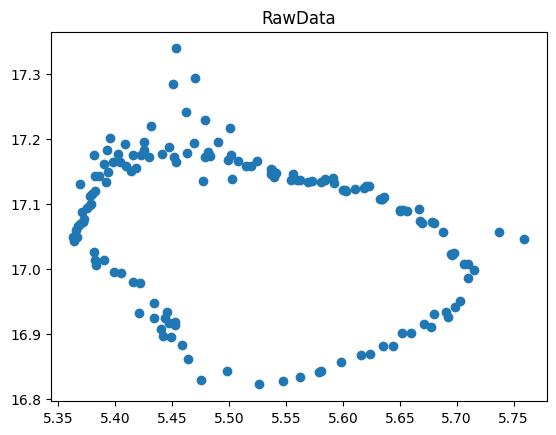

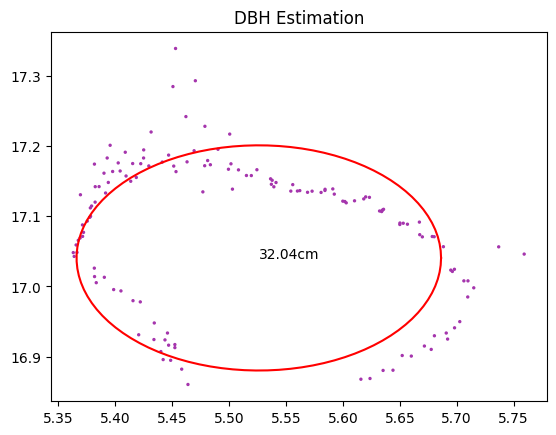

6 DBH is: 32.03698275132185 cm
********************
7 TreeHeight is: 0.5765999999999991 m
7 DBH is: 0 cm
********************
8 TreeHeight is: 1.679700000000004 m
8 DBH is: 16.180573367818127 cm
********************
9 TreeHeight is: 7.711500000000001 m
9 DBH is: 19.21325785405637 cm
********************
10 TreeHeight is: 0.1372 m
10 DBH is: 0 cm
********************
11 TreeHeight is: 0.4908000000000001 m
11 DBH is: 0 cm
********************
12 TreeHeight is: 0.49210000000000065 m
12 DBH is: 0 cm
********************
13 TreeHeight is: 0.056800000000002626 m
13 DBH is: 0 cm
********************
14 TreeHeight is: 0.3411000000000044 m
14 DBH is: 0 cm
********************
15 TreeHeight is: 7.235199999999999 m
15 DBH is: 13.67312227454372 cm
********************
16 TreeHeight is: 1.3200000000000003 m
16 DBH is: 14.046021655462237 cm
********************


D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:263: RuntimeWarning: Degrees of freedom <= 0 for slice
  keepdims=keepdims, where=where)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:223: RuntimeWarning: invalid value encountered in true_divide
  subok=False)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\_methods.py:254: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
D:\Programs\anaconda3\envs\LiDAR_env\lib\site-packages\numpy\core\fromnumeric.py:3441: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)
D:\Programs\anaconda3\envs\L

In [3]:
saveid = 6     #保存编号为2的提取结果
for id in np.sort(Label):
    pcd = pointcloud[pointcloud['Segmentation']==id]     #筛选出编号为1的树木

    if id == saveid:
        pcd.to_csv(os.path.join(spth,'SingleTree.xyz'), sep='\t', index=False)  # 保存编号为1的树木点云

    xyz = np.asarray(pcd[['x','y','z']].values)
    x, y, z = xyz[:, 0], xyz[:, 1], xyz[:,2]
    pcd_show = o3d.geometry.PointCloud()        # 点云可视化
    pcd_show.points = o3d.utility.Vector3dVector(xyz)
    if id == saveid:
        o3d.visualization.draw_geometries([pcd_show])


    ##--------------------------提取树高--------------------------
    TreeHight = np.max(xyz[:,2]) - np.min(xyz[:,2])
    print(str(int(id))+' TreeHeight is:' , TreeHight,'m')


    ##--------------------------提取距离地面点1.3m距离的点云数据--------------------------
    index = (z >= np.min(z)+1.2) & (z <= np.min(z)+1.3)
    xyz = xyz[index]
    if id == saveid:
        plt.scatter(xyz[:,0],xyz[:,1])        # 可视化PCA变换结果
        plt.title('RawData')
        plt.show()
        plt.close()

    ##--------------------------DBSCAN聚类分析--------------------------
    try:
        eps = 0.1
        min_samples = 20
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(xyz)
        num_clusters = max(labels) + 1
        clusters = [xyz[labels == i] for i in range(num_clusters)]
    except:
        clusters = [xyz]


    ##--------------------------逐类点云圆形拟合--------------------------
    maxradius = 0
    for i, cluster_points in enumerate(clusters):
        try:
            cluster_color = [np.random.rand(3)] * len(cluster_points)
            x, y = cluster_points[:, 0], cluster_points[:, 1]
            plt.scatter(x,y,color=cluster_color,s=2)

            xy = np.vstack((x, y))
            initial_guess = [np.mean(x), np.mean(y), np.std(np.sqrt((x - np.mean(x)) ** 2 + (y - np.mean(y)) ** 2))]
            params, covariance = curve_fit(circle_fit_func, xy, np.zeros_like(x), p0=initial_guess)     # 点云圆形拟合
            cx, cy, radius = params     # 获取圆形中心坐标与半径

            theta = np.linspace(0, 2 * np.pi, 100)      # 生成角度数组
            x = cx + radius * np.cos(theta)     # 计算圆周上的 x 坐标
            y = cy + radius * np.sin(theta)     # 计算圆周上的 y 坐标
            plt.plot(x, y, color='red')     #可视化点云数据
            plt.title('DBH Estimation')
            plt.text(cx, cy, str(np.round(radius * 2 * 100, 2)) + 'cm')
            maxradius = max(maxradius,radius * 2 * 100)
        except:
            continue

    if id == saveid:
        plt.savefig(os.path.join(spth, 'DBH.png'))
        plt.show()
    plt.close()
    print(str(int(id)) + ' DBH is:', maxradius, 'cm')
    print('*' * 20)